# Modelado — Estrategias frente al desbalance de clases
**Curso:** Machine Learning Applied — Short-Paper (versión final)

**Autores:** Jose Muñoz Ríos, Santiago Álvarez Peña

Este notebook respalda las secciones de **Metodología, Resultados y Discusión** de la versión final del paper. Atiende la retroalimentación de la primera entrega: la línea base pasa a ser el modelo **sin tratamiento del desbalance**, y se comparan varias estrategias: **pesos por clase**, sobremuestreo con **SMOTENC** y **SMOTEN** (variantes de SMOTE para variables categóricas), **AdaBoost** como modelo adicional y **ajuste del umbral de decisión**. Además de F1-macro y recall por clase, se reportan la **exactitud** y el **F1 ponderado**, que son las métricas usadas en la literatura sobre este dataset.

Parte de `cleaned.csv` (generado por `data_s5_eda.ipynb`): 22 predictoras + `Accident_severity` (0 = Fatal, 1 = Serious, 2 = Slight).

Dependencias: `pandas`, `numpy`, `matplotlib`, `scikit-learn` (≥ 1.4) e `imbalanced-learn` (≥ 0.12). Tiempo de ejecución aproximado: 1 hora.

In [1]:
import os, time, warnings
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_val_predict, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, recall_score,
                             precision_score, roc_auc_score, confusion_matrix, classification_report)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTENC, SMOTEN
from imblearn.ensemble import RUSBoostClassifier, EasyEnsembleClassifier

warnings.filterwarnings('ignore')
os.makedirs('figuras', exist_ok=True)
os.makedirs('resultados', exist_ok=True)
SEED = 42
CLASES = ['Fatal', 'Serious', 'Slight']

df = pd.read_csv('cleaned.csv')
raw = pd.read_csv('RTA_Dataset.csv')
assert len(df) == len(raw)
X = df.drop(columns='Accident_severity')
y = df['Accident_severity'].to_numpy()
X.shape, np.bincount(y)

((12316, 22), array([  158,  1743, 10415]))

## 1. Grupos de siniestro y partición entrenamiento/prueba

Cada fila es un conductor o vehículo, y varias filas pertenecen al mismo siniestro (EDA, sección 2). Se reconstruye un identificador aproximado de siniestro y se usa `StratifiedGroupKFold`: todas las filas de un siniestro quedan del mismo lado y se conserva la proporción de clases. Uno de los 5 folds (≈ 20%) es el conjunto de prueba, que solo se usa en la evaluación final. Es la misma partición de la primera entrega, así que los resultados son comparables.

In [2]:
cols_evento = ['Time', 'Day_of_week', 'Number_of_vehicles_involved', 'Number_of_casualties',
               'Light_conditions', 'Weather_conditions', 'Road_surface_conditions']
groups = raw.groupby(cols_evento, dropna=False).ngroup().to_numpy()

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_tr, idx_te = next(outer.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y[idx_tr], y[idx_te]
g_tr, g_te = groups[idx_tr], groups[idx_te]
assert len(set(g_tr) & set(g_te)) == 0

particion = pd.DataFrame({
    'conjunto': ['Entrenamiento', 'Prueba'],
    'registros': [len(y_tr), len(y_te)],
    'siniestros': [len(np.unique(g_tr)), len(np.unique(g_te))],
    'Fatal': [np.sum(y_tr == 0), np.sum(y_te == 0)],
    'Serious': [np.sum(y_tr == 1), np.sum(y_te == 1)],
    'Slight': [np.sum(y_tr == 2), np.sum(y_te == 2)],
})
particion.to_csv('resultados/particion.csv', index=False)
particion

,conjunto,registros,siniestros,Fatal,Serious,Slight
0,Entrenamiento,9853,4209,126,1395,8332
1,Prueba,2463,1063,32,348,2083


**Observación:** 9,853 registros de entrenamiento y 2,463 de prueba, sin siniestros compartidos. El conjunto de prueba tiene solo 32 casos fatales, así que el recall de esa clase es muy inestable (cada caso equivale a ~3 puntos).

## 2. Preprocesamiento

Dentro del pipeline (se ajusta solo con el entrenamiento de cada fold): one-hot para las 20 variables categóricas, agrupando las categorías con menos del 1% de los registros; codificación cíclica de `Hour`; estandarización de `Number_of_vehicles_involved`.

In [3]:
cat_cols = X.select_dtypes(exclude='number').columns.tolist()
num_cols = ['Hour', 'Number_of_vehicles_involved']

def hora_ciclica(h):
    h = np.asarray(h, dtype=float)
    return np.c_[np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)]

preproc = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01, sparse_output=False), cat_cols),
    ('hora', FunctionTransformer(hora_ciclica), ['Hour']),
    ('num', StandardScaler(), ['Number_of_vehicles_involved']),
])
print('Categóricas:', len(cat_cols), '| Numéricas:', num_cols)

Categóricas: 20 | Numéricas: ['Hour', 'Number_of_vehicles_involved']


## 3. Estrategias frente al desbalance

| Estrategia | Qué hace |
|---|---|
| **Sin tratamiento** (línea base) | El modelo se entrena con la distribución original (84.6 / 14.2 / 1.3%). |
| **Pesos por clase** | Penaliza más los errores en las clases minoritarias: pesos inversos a la frecuencia (`balanced`) o su raíz cuadrada (más suaves). |
| **SMOTENC** | Crea registros sintéticos de las clases minoritarias interpolando entre vecinos: las variables numéricas se interpolan y las categóricas toman el valor más frecuente entre los vecinos. |
| **SMOTEN** | Igual que SMOTENC, pero trata todas las variables como categóricas (aquí también la hora y el número de vehículos), con una distancia para categorías (VDM). |

Para el sobremuestreo se prueban dos niveles: balance completo (`auto`) o llevar cada clase minoritaria al 50% de la mayoritaria. El sobremuestreo ocurre **dentro del pipeline**, es decir, solo sobre el entrenamiento de cada fold: los registros sintéticos nunca llegan a validación ni a prueba.

Se combinan con tres modelos de árboles: **Random Forest**, **Histogram Gradient Boosting** y **AdaBoost** (árboles poco profundos que se entrenan en secuencia, dando más peso a los registros mal clasificados). La Regresión Logística de la primera entrega quedó por debajo de los modelos de árboles, así que no se repite.

In [4]:
conteo = np.bincount(y_tr)
w_bal = len(y_tr) / (3 * conteo)
W_SQRT = {i: round(float(w), 2) for i, w in enumerate(np.sqrt(w_bal / w_bal[2]))}
print('Pesos suavizados (raíz):', W_SQRT)

def mitad_mayoritaria(y):
    # lleva cada clase minoritaria al 50% de la mayoritaria
    c = Counter(y)
    maj = max(c.values())
    return {k: max(v, int(0.5 * maj)) for k, v in c.items() if v < maj}

def a_categorica(D):
    D = D.copy(); D[num_cols] = D[num_cols].astype(str); return D

def a_numerica(D):
    D = D.copy(); D[num_cols] = D[num_cols].astype(int); return D

MODELOS = {
    # Grillas pequeñas y fijas: las mismas para todas las estrategias de un modelo, para que las
    # diferencias se deban a la estrategia. Incluyen las mejores configuraciones de la primera entrega.
    'Random Forest': (RandomForestClassifier(n_estimators=300, max_features=0.2, n_jobs=-1, random_state=SEED), {
        'clf__max_depth': [10, None], 'clf__min_samples_leaf': [10, 30]}),
    'Gradient Boosting': (HistGradientBoostingClassifier(max_iter=300, max_leaf_nodes=31, min_samples_leaf=100,
                                                         l2_regularization=1, early_stopping=False, random_state=SEED), {
        'clf__learning_rate': [0.05, 0.1], 'clf__max_depth': [3, None]}),
    'AdaBoost': (AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=SEED), n_estimators=300, random_state=SEED), {
        'clf__estimator__max_depth': [2, 3], 'clf__learning_rate': [0.1, 0.5]}),
}

def construir(estrategia, modelo):
    clf, espacio = MODELOS[modelo]
    espacio = dict(espacio)
    pasos = []
    if estrategia == 'SMOTENC':
        pasos.append(('muestreo', SMOTENC(categorical_features=cat_cols, random_state=SEED)))
        espacio['muestreo__sampling_strategy'] = ['auto', mitad_mayoritaria]
    elif estrategia == 'SMOTEN':
        pasos += [('a_cat', FunctionTransformer(a_categorica)),
                  ('muestreo', SMOTEN(random_state=SEED)),
                  ('a_num', FunctionTransformer(a_numerica))]
        espacio['muestreo__sampling_strategy'] = ['auto', mitad_mayoritaria]
    elif estrategia == 'Pesos por clase':
        clave = 'clf__estimator__class_weight' if modelo == 'AdaBoost' else 'clf__class_weight'
        espacio[clave] = ['balanced_subsample' if modelo == 'Random Forest' else 'balanced', W_SQRT]
    pasos += [('pre', preproc), ('clf', clf)]
    return Pipeline(pasos), espacio

ESTRATEGIAS = ['Sin tratamiento', 'Pesos por clase', 'SMOTENC', 'SMOTEN']

Pesos suavizados (raíz): {0: 8.13, 1: 2.44, 2: 1.0}


## 4. Búsqueda de hiperparámetros por estrategia y modelo

Para cada combinación (4 estrategias × 3 modelos) se hace una **búsqueda en grilla** con **validación cruzada de 5 folds por grupos de siniestro**, maximizando el **F1-macro** (da el mismo peso a las tres clases). La grilla de cada modelo es la misma en todas las estrategias (4 combinaciones; 8 cuando la estrategia agrega su propio parámetro: tipo de peso o nivel de sobremuestreo), de modo que las diferencias se deban a la estrategia y no a la suerte de la búsqueda. Incluye las mejores configuraciones de la primera entrega.

In [5]:
cv_grupos = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=0)
busquedas, filas_cv = {}, []
t0 = time.time()
for estrategia in ESTRATEGIAS:
    for modelo in MODELOS:
        pipe, espacio = construir(estrategia, modelo)
        rs = GridSearchCV(pipe, espacio, scoring='f1_macro', cv=cv_grupos, n_jobs=1)
        rs.fit(X_tr, y_tr, groups=g_tr)
        busquedas[(estrategia, modelo)] = rs
        mejores = {k.split('__', 1)[1]: (v.__name__ if callable(v) else v) for k, v in rs.best_params_.items()}
        filas_cv.append({'estrategia': estrategia, 'modelo': modelo,
                         'F1-macro CV (media)': rs.best_score_,
                         'F1-macro CV (desv.)': rs.cv_results_['std_test_score'][rs.best_index_],
                         'mejores hiperparámetros': mejores})
        print(f'{estrategia:16s} {modelo:18s} F1-macro CV = {rs.best_score_:.3f}  ({time.time() - t0:.0f} s)', flush=True)

tabla_cv = pd.DataFrame(filas_cv)
tabla_cv.to_csv('resultados/cv_estrategias.csv', index=False)
tabla_cv.pivot(index='estrategia', columns='modelo', values='F1-macro CV (media)').loc[ESTRATEGIAS].round(3)

Sin tratamiento  Random Forest      F1-macro CV = 0.305  (44 s)


Sin tratamiento  Gradient Boosting  F1-macro CV = 0.329  (175 s)


Sin tratamiento  AdaBoost           F1-macro CV = 0.324  (337 s)


Pesos por clase  Random Forest      F1-macro CV = 0.385  (428 s)


Pesos por clase  Gradient Boosting  F1-macro CV = 0.367  (669 s)


...

SMOTENC          AdaBoost           F1-macro CV = 0.357  (1998 s)


SMOTEN           Random Forest      F1-macro CV = 0.338  (2191 s)


SMOTEN           Gradient Boosting  F1-macro CV = 0.350  (2577 s)


SMOTEN           AdaBoost           F1-macro CV = 0.356  (3327 s)


modelo,AdaBoost,Gradient Boosting,Random Forest
estrategia,,,
Sin tratamiento,0.324,0.329,0.305
Pesos por clase,0.348,0.367,0.385
SMOTENC,0.357,0.351,0.357
SMOTEN,0.356,0.350,0.338


In [6]:
mejor_clave = max(busquedas, key=lambda k: busquedas[k].best_score_)
print('Mejor combinación en validación cruzada:', mejor_clave, round(busquedas[mejor_clave].best_score_, 3))

Mejor combinación en validación cruzada: ('Pesos por clase', 'Random Forest') 0.385


**Observación:** todas las estrategias de balanceo superan a la línea base sin tratamiento (F1-macro 0.31–0.33), pero con márgenes modestos. La mejor combinación es **Random Forest con pesos por clase** (0.385), seguida de Gradient Boosting con pesos (0.367). SMOTENC y SMOTEN quedan entre 0.34 y 0.36 con los tres modelos, y, entre las estrategias de balanceo, AdaBoost solo supera a Random Forest con SMOTEN (0.356 frente a 0.338). La desviación entre folds (0.005–0.019) es comparable a varias de estas diferencias: la ventaja de Random Forest con pesos es la única que destaca, y por poco más de una desviación.

### 4.1 Otras variantes de AdaBoost para desbalance (descartadas)

`imbalanced-learn` incluye dos variantes de AdaBoost pensadas para clases desbalanceadas: **RUSBoost** (submuestrea la clase mayoritaria en cada iteración) y **EasyEnsemble** (varios AdaBoost entrenados sobre subconjuntos balanceados). Se prueban con la misma validación por grupos.

In [7]:
variantes = {
    'RUSBoost': Pipeline([('pre', preproc), ('clf', RUSBoostClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=300, learning_rate=0.5, random_state=SEED))]),
    'EasyEnsemble': Pipeline([('pre', preproc), ('clf', EasyEnsembleClassifier(n_estimators=10, random_state=SEED))]),
}
filas_var = []
for nombre, pipe in variantes.items():
    try:
        f = cross_val_score(pipe, X_tr, y_tr, groups=g_tr, cv=cv_grupos, scoring='f1_macro', error_score='raise')
        filas_var.append({'variante': nombre, 'F1-macro CV': round(f.mean(), 3), 'nota': ''})
    except Exception as e:
        filas_var.append({'variante': nombre, 'F1-macro CV': np.nan, 'nota': str(e)[:90]})
pd.DataFrame(filas_var)

,variante,F1-macro CV,nota
0,RUSBoost,NaN,BaseClassifier in AdaBoostClassifier ensemble ...
1,EasyEnsemble,0.3,


**Observación:** RUSBoost no logra entrenar: con tan pocos casos fatales, el submuestreo deja conjuntos en los que el árbol base es peor que el azar y AdaBoost se detiene. EasyEnsemble obtiene un F1-macro de 0.30, por debajo de la línea base, porque al balancear por submuestreo descarta la mayoría de los registros leves. Por eso no se incluyen en la comparación principal.

## 5. Evaluación en el conjunto de prueba

In [8]:
def metricas(estrategia, modelo, pred, proba=None):
    rec = recall_score(y_te, pred, average=None, labels=[0, 1, 2], zero_division=0)
    prec = precision_score(y_te, pred, average=None, labels=[0, 1, 2], zero_division=0)
    fila = {'estrategia': estrategia, 'modelo': modelo,
            'Exactitud': accuracy_score(y_te, pred),
            'Exactitud balanceada': balanced_accuracy_score(y_te, pred),
            'F1-macro': f1_score(y_te, pred, average='macro'),
            'F1 ponderado': f1_score(y_te, pred, average='weighted'),
            'Recall Fatal': rec[0], 'Recall Serious': rec[1], 'Recall Slight': rec[2],
            'Precisión Fatal': prec[0], 'Precisión Serious': prec[1]}
    fila['AUC macro (OvR)'] = roc_auc_score(y_te, proba, multi_class='ovr') if proba is not None else np.nan
    return fila

dummy = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)
filas_test = [metricas('Clase mayoritaria', '-', dummy.predict(X_te))]
for (estrategia, modelo), rs in busquedas.items():
    est = rs.best_estimator_
    filas_test.append(metricas(estrategia, modelo, est.predict(X_te), est.predict_proba(X_te)))
tabla_test = pd.DataFrame(filas_test)
tabla_test.to_csv('resultados/prueba_estrategias.csv', index=False)
tabla_test.round(3)

,estrategia,modelo,Exactitud,Exactitud balanceada,F1-macro,F1 ponderado,Recall Fatal,Recall Serious,Recall Slight,Precisión Fatal,Precisión Serious,AUC macro (OvR)
0,Clase mayoritaria,-,0.846,0.333,0.305,0.775,0.000,0.000,1.000,0.000,0.000,NaN
1,Sin tratamiento,Random Forest,0.846,0.333,0.305,0.775,0.000,0.000,1.000,0.000,0.000,0.571
2,Sin tratamiento,Gradient Boosting,0.825,0.342,0.333,0.778,0.000,0.060,0.965,0.000,0.221,0.528
3,Sin tratamiento,AdaBoost,0.843,0.346,0.334,0.786,0.000,0.049,0.988,0.000,0.405,0.539
4,Pesos por clase,Random Forest,0.740,0.371,0.366,0.751,0.000,0.284,0.827,0.000,0.225,0.528
5,Pesos por clase,Gradient Boosting,0.695,0.368,0.353,0.721,0.000,0.339,0.765,0.000,0.196,0.548
6,Pesos por clase,AdaBoost,0.826,0.363,0.365,0.791,0.000,0.135,0.954,0.000,0.318,0.512
7,SMOTENC,Random Forest,0.744,0.349,0.348,0.747,0.000,0.201,0.846,0.000,0.188,0.524
8,SMOTENC,Gradient Boosting,0.769,0.351,0.350,0.759,0.031,0.135,0.887,0.016,0.193,0.531
9,SMOTENC,AdaBoost,0.758,0.355,0.355,0.756,0.031,0.167,0.868,0.014,0.204,0.525


**Observación:** en prueba, ningún modelo supera un F1-macro de 0.37 ni detecta de forma útil la clase Fatal: el mayor recall fatal es 0.06 (2 de 32 casos), con SMOTEN + AdaBoost. Los modelos sin tratamiento tienen la exactitud más alta (0.83–0.85) y un F1 ponderado de 0.78–0.79, pero casi no detectan graves (recall ≤ 0.06). Las estrategias de balanceo cambian exactitud por detección de graves: con pesos, Random Forest detecta el 28% de los graves con una exactitud de 0.74. El F1 ponderado apenas cambia entre estrategias (0.72–0.79), así que tampoco sirve para comparar modelos en este problema.

## 6. Ajuste del umbral de decisión

Los modelos predicen la clase con mayor probabilidad, lo que favorece a la clase mayoritaria. Como estrategia adicional, se multiplican las probabilidades de Fatal y Serious por factores (w_F, w_S) antes de elegir la clase. Los factores se eligen con **predicciones fuera de fold** del entrenamiento (validación por grupos), maximizando el F1-macro, y luego se aplican **sin cambios** al conjunto de prueba. Se aplica a la mejor combinación de la validación cruzada.

In [9]:
mejor = busquedas[mejor_clave].best_estimator_
proba_oof = cross_val_predict(clone(mejor), X_tr, y_tr, groups=g_tr, cv=cv_grupos, method='predict_proba')

def predecir(p, wF, wS):
    return np.argmax(p * np.array([wF, wS, 1.0]), axis=1)

grid_F = [1, 1.5, 2, 3, 5, 8, 12, 20, 30, 50]
grid_S = [1, 1.25, 1.5, 2, 2.5, 3, 4, 6]
res = [(wF, wS, f1_score(y_tr, predecir(proba_oof, wF, wS), average='macro')) for wF in grid_F for wS in grid_S]
wF, wS, f1_oof = max(res, key=lambda r: r[2])
f1_oof_sin = f1_score(y_tr, predecir(proba_oof, 1, 1), average='macro')
print(f'Factores elegidos: w_F = {wF}, w_S = {wS} | F1-macro fuera de fold: {f1_oof_sin:.3f} -> {f1_oof:.3f}')

proba_te = mejor.predict_proba(X_te)
pred_umbral = predecir(proba_te, wF, wS)
fila_umbral = metricas(mejor_clave[0] + ' + umbral', mejor_clave[1], pred_umbral, proba_te)
pd.DataFrame([{'w_F': wF, 'w_S': wS, 'F1-macro OOF sin ajuste': f1_oof_sin, 'F1-macro OOF con ajuste': f1_oof}]).to_csv('resultados/umbral.csv', index=False)
tabla_test = pd.concat([tabla_test, pd.DataFrame([fila_umbral])], ignore_index=True)
tabla_test.to_csv('resultados/prueba_estrategias.csv', index=False)
tabla_test.round(3).tail(2)

Factores elegidos: w_F = 1, w_S = 1 | F1-macro fuera de fold: 0.387 -> 0.387


,estrategia,modelo,Exactitud,Exactitud balanceada,F1-macro,F1 ponderado,Recall Fatal,Recall Serious,Recall Slight,Precisión Fatal,Precisión Serious,AUC macro (OvR)
12,SMOTEN,AdaBoost,0.758,0.371,0.370,0.756,0.062,0.184,0.865,0.054,0.197,0.558
13,Pesos por clase + umbral,Random Forest,0.740,0.371,0.366,0.751,0.000,0.284,0.827,0.000,0.225,0.528


**Observación:** para el mejor modelo (Random Forest con pesos por clase), los factores que maximizan el F1-macro fuera de fold son w_F = 1 y w_S = 1, es decir, no mover el umbral. Los pesos por clase ya desplazan la decisión hacia las clases minoritarias, y aumentar la probabilidad de Fatal genera muchos más falsos positivos que aciertos. El ajuste de umbral no mejora este modelo.

## 7. Mejor configuración de cada estrategia (tabla del paper)

In [10]:
# Para cada estrategia se toma el modelo con mejor F1-macro en validación cruzada (no en prueba)
mejores_por_estrategia = tabla_cv.loc[tabla_cv.groupby('estrategia')['F1-macro CV (media)'].idxmax(), ['estrategia', 'modelo']]
resumen = tabla_test.merge(mejores_por_estrategia, on=['estrategia', 'modelo'])
resumen = pd.concat([resumen, tabla_test[tabla_test['estrategia'].str.endswith('+ umbral')]], ignore_index=True)
orden = ESTRATEGIAS + [mejor_clave[0] + ' + umbral']
resumen['orden'] = resumen['estrategia'].map({e: i for i, e in enumerate(orden)})
resumen = resumen.sort_values('orden').drop(columns='orden')
resumen.to_csv('resultados/resumen_paper.csv', index=False)
resumen[['estrategia', 'modelo', 'Exactitud', 'F1 ponderado', 'F1-macro', 'Recall Fatal', 'Recall Serious', 'Recall Slight']].round(3)

,estrategia,modelo,Exactitud,F1 ponderado,F1-macro,Recall Fatal,Recall Serious,Recall Slight
0,Sin tratamiento,Gradient Boosting,0.825,0.778,0.333,0.000,0.060,0.965
1,Pesos por clase,Random Forest,0.740,0.751,0.366,0.000,0.284,0.827
2,SMOTENC,Random Forest,0.744,0.747,0.348,0.000,0.201,0.846
3,SMOTEN,AdaBoost,0.758,0.756,0.370,0.062,0.184,0.865
4,Pesos por clase + umbral,Random Forest,0.740,0.751,0.366,0.000,0.284,0.827


In [11]:
final_pred = pred_umbral
print('Modelo final:', mejor_clave, f'+ umbral (w_F={wF}, w_S={wS})')
print(classification_report(y_te, final_pred, target_names=CLASES, digits=3, zero_division=0))
cm = confusion_matrix(y_te, final_pred, labels=[0, 1, 2])
pd.DataFrame(cm, index=[f'real {c}' for c in CLASES], columns=[f'pred {c}' for c in CLASES])

Modelo final: ('Pesos por clase', 'Random Forest') + umbral (w_F=1, w_S=1)
              precision    recall  f1-score   support

       Fatal      0.000     0.000     0.000        32
     Serious      0.225     0.284     0.251       348
      Slight      0.865     0.827     0.846      2083

    accuracy                          0.740      2463
   macro avg      0.363     0.371     0.366      2463
weighted avg      0.763     0.740     0.751      2463



,pred Fatal,pred Serious,pred Slight
real Fatal,0,6,26
real Serious,6,99,243
real Slight,25,335,1723


**Observación:** el modelo final (Random Forest con pesos por clase) obtiene en prueba un F1-macro de 0.37 y una exactitud de 0.74. Detecta el 28% de los accidentes graves con una precisión de 0.23, y ninguno de los 32 fatales: 26 se clasifican como leves y 6 como graves (81% y 19%).

## 8. Figuras

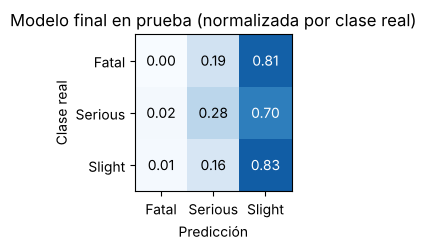

In [12]:
# Matriz de confusión del modelo final (solo en el notebook)
fig, ax = plt.subplots(figsize=(3.2, 2.6))
cm_norm = cm / cm.sum(axis=1, keepdims=True)
ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f'{cm_norm[i, j]:.2f}', ha='center', va='center', color='white' if cm_norm[i, j] > 0.5 else 'black')
ax.set_xticks(range(3), CLASES)
ax.set_yticks(range(3), CLASES)
ax.set_xlabel('Predicción'); ax.set_ylabel('Clase real')
ax.set_title('Modelo final en prueba (normalizada por clase real)')
plt.tight_layout(); plt.show()

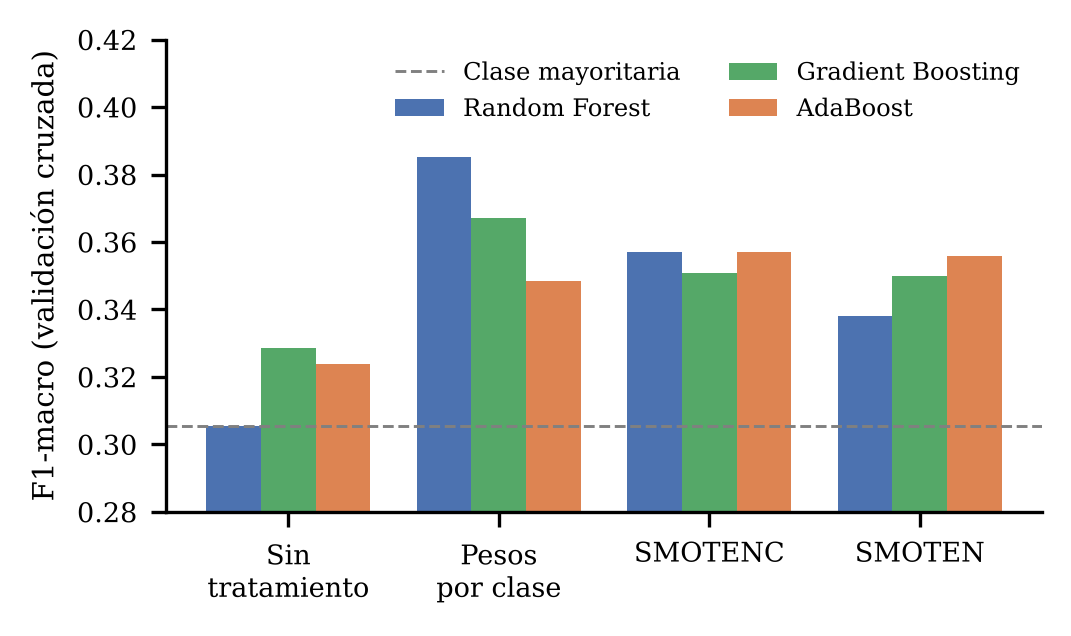

In [13]:
# Fig. 2 del paper: F1-macro en validación cruzada por estrategia y modelo
plt.rcParams.update({'font.family': 'serif', 'font.size': 7, 'axes.titlesize': 7.5,
                     'axes.labelsize': 7, 'xtick.labelsize': 6.5, 'ytick.labelsize': 6.5})
fig, ax = plt.subplots(figsize=(3.45, 2.0), dpi=300)
piv = tabla_cv.pivot(index='estrategia', columns='modelo', values='F1-macro CV (media)').loc[ESTRATEGIAS]
etiquetas = ['Sin\ntratamiento', 'Pesos\npor clase', 'SMOTENC', 'SMOTEN']
colores = {'Random Forest': '#4C72B0', 'Gradient Boosting': '#55A868', 'AdaBoost': '#DD8452'}
nombres = {'Random Forest': 'Random Forest', 'Gradient Boosting': 'Gradient Boosting', 'AdaBoost': 'AdaBoost'}
ancho = 0.26
xpos = np.arange(len(ESTRATEGIAS))
for i, m in enumerate(['Random Forest', 'Gradient Boosting', 'AdaBoost']):
    ax.bar(xpos + (i - 1) * ancho, piv[m], ancho, color=colores[m], label=nombres[m])
base_cv = f1_score(y_tr, np.full_like(y_tr, 2), average='macro')
ax.axhline(base_cv, color='gray', ls='--', lw=0.7, label='Clase mayoritaria')
ax.set_xticks(xpos, etiquetas)
ax.set_ylim(0.28, 0.42)
ax.set_ylabel('F1-macro (validación cruzada)')
ax.legend(fontsize=5.8, frameon=False, loc='upper right', ncol=2)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(pad=0.4)
fig.savefig('figuras/fig3_estrategias.png', dpi=300)
plt.show()
plt.rcParams.update(plt.rcParamsDefault)

**Observación:** las estrategias de balanceo superan a la línea base sin tratamiento y a la clase mayoritaria (línea punteada), pero sus valores se agrupan entre 0.34 y 0.39; solo Random Forest con pesos por clase destaca. La matriz de confusión del modelo final (sección 7) muestra que el 81% de los casos fatales se clasifica como leve.

## 9. Conclusiones del modelado

- La línea base sin tratamiento del desbalance predice casi siempre «leve»: exactitud de 0.83–0.85, pero F1-macro de 0.31–0.33.
- Todas las estrategias de balanceo mejoran el F1-macro, pero dentro de un rango estrecho (0.34–0.39 en validación cruzada y 0.34–0.37 en prueba). La mejor sigue siendo Random Forest con pesos por clase; SMOTENC, SMOTEN y AdaBoost no la superan, y el ajuste de umbral no aporta.
- Ninguna estrategia resuelve la clase Fatal (recall máximo de 0.06). Que técnicas tan distintas lleguen al mismo techo indica que el límite está en la información que aportan las variables, más que en el método de balanceo.
- RUSBoost y EasyEnsemble se descartaron (sección 4.1).